# Савинский Владимир Олегович, ИКБО-40-23, практическая работа №1 Технологии и инструментарий анализа больших данных
выполнено 05.09.2026

In [41]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import kagglehub
import os
from pathlib import Path
import matplotlib.pyplot as plt
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.12.4
pandas: 3.0.5
NumPy: 2.5.2
Matplotlib: 3.11.1


In [42]:
os.environ["KAGGLEHUB_CACHE"] = "data/kagglehub_cache"

In [43]:
path = kagglehub.dataset_download("denkuznetz/taxi-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: data/kagglehub_cache\datasets\denkuznetz\taxi-price-prediction\versions\1


In [44]:
file_path = Path(path + "/taxi_trip_pricing.csv")
df = pd.read_csv(file_path)


In [45]:
print("Размер файла:", file_path.stat().st_size, "байт")

print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество строк:", len(df))
print("Количество столбцов:", len(df.columns))

Размер файла: 67269 байт

Типы данных:
Trip_Distance_km         float64
Time_of_Day                  str
Day_of_Week                  str
Passenger_Count          float64
Traffic_Conditions           str
Weather                      str
Base_Fare                float64
Per_Km_Rate              float64
Per_Minute_Rate          float64
Trip_Duration_Minutes    float64
Trip_Price               float64
dtype: object

Количество строк: 1000
Количество столбцов: 11


In [46]:
with open(file_path, "r", encoding="utf-8") as f:
    for i in range(3):
        print(f.readline().strip())

Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
19.35,Morning,Weekday,3.0,Low,Clear,3.56,0.8,0.32,53.82,36.2624
47.59,Afternoon,Weekday,1.0,High,Clear,,0.62,0.43,40.57,


# Паспорт данных
Датасет взят с открытого ресурса для соревнований Kaggle: https://www.kaggle.com/datasets/denkuznetz/taxi-price-prediction

Этот набор данных предназначен для прогнозирования стоимости поездок на такси на основе различных факторов: расстояния, времени суток, дорожной обстановки и других. Он содержит реалистичные синтетические данные для задач регрессии и даёт возможность исследовать ценовые тренды в индустрии такси.

Цель анализа данного датасета: подготовка данных к решению задачи регрессии стоимости поездки в зависимости от её характеристик.

Данные в этом наборе являются синтетическими и были сгенерированы программно для имитации реалистичного сценария прогнозирования тарифов на такси. Они не взяты из реальных сервисов такси или внешних баз данных. Синтетические данные созданы с помощью методов генерации случайных чисел в Python с использованием библиотек NumPy и Pandas, чтобы имитировать ключевые факторы, влияющие на стоимость поездки: расстояние, количество пассажиров, время суток, дорожную обстановку и погодные условия.

Предметная область: поездки на такси.
Размер таблицы: 1000 x 11.

Перечень признаков:
- Trip_Distance_km: дистанция поездки в км;
- Time_of_Day: часть дня, в которую началась поездка (категориальный признак: утро, день, вечер, ночь);
- Day_of_Week: является день, в который совершена поездка, будним или выходным;
- Passenger_Count: количество пассажиров в машине во время поездки;
- Traffic_Conditions: интенсивность траффика во время поездки (категориальный признак: низкая, средняя, высокая);
- Weather: погодные условия во время поездки (категориальный признак: хорошая, дождливая, снежная);
- Base_Fare: базовый тариф без учета времени или дистанции поездки;
- Per_Km_Rate: ставка, взимаемая за километр пути;
- Per_Minute_Rate: ставка, взимаемая за минуту пути;
- Trip_Duration_Minutes: длительность поездки в минутах;
- Trip_Price: стоимось поездки (единицы измерения не указаны).

In [47]:
display(df.head(10))
df.info()
display(df.describe(include="all").T)

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,Morning,Weekday,3.0,Low,Clear,3.56,0.80,0.32,53.82,36.2624
1,47.59,Afternoon,Weekday,1.0,High,Clear,NaN,0.62,0.43,40.57,NaN
2,36.87,Evening,Weekend,1.0,High,Clear,2.70,1.21,0.15,37.27,52.9032
3,30.33,Evening,Weekday,4.0,Low,NaN,3.48,0.51,0.15,116.81,36.4698
4,NaN,Evening,Weekday,3.0,High,Clear,2.93,0.63,0.32,22.64,15.6180
5,8.64,Afternoon,Weekend,2.0,Medium,Clear,2.55,1.71,0.48,89.33,60.2028
6,3.85,Afternoon,Weekday,4.0,High,Rain,3.51,1.66,NaN,5.05,11.2645
7,43.44,Evening,Weekend,3.0,NaN,Clear,2.97,1.87,0.23,NaN,101.1216
8,30.45,Morning,Weekday,3.0,High,Clear,2.77,1.78,0.34,110.33,NaN
9,35.70,Afternoon,Weekday,2.0,Low,Rain,3.39,1.52,0.47,NaN,75.5657


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Trip_Distance_km       950 non-null    float64
 1   Time_of_Day            950 non-null    str    
 2   Day_of_Week            950 non-null    str    
 3   Passenger_Count        950 non-null    float64
 4   Traffic_Conditions     950 non-null    str    
 5   Weather                950 non-null    str    
 6   Base_Fare              950 non-null    float64
 7   Per_Km_Rate            950 non-null    float64
 8   Per_Minute_Rate        950 non-null    float64
 9   Trip_Duration_Minutes  950 non-null    float64
 10  Trip_Price             951 non-null    float64
dtypes: float64(7), str(4)
memory usage: 108.5 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Trip_Distance_km,950.0,NaN,NaN,NaN,27.070547,19.9053,1.23,12.6325,25.83,38.405,146.067047
Time_of_Day,950,4,Afternoon,371,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day_of_Week,950,2,Weekday,655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Passenger_Count,950.0,NaN,NaN,NaN,2.476842,1.102249,1.0,1.25,2.0,3.0,4.0
Traffic_Conditions,950,3,Low,397,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weather,950,3,Clear,667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Base_Fare,950.0,NaN,NaN,NaN,3.502989,0.870162,2.01,2.73,3.52,4.26,5.0
Per_Km_Rate,950.0,NaN,NaN,NaN,1.233316,0.429816,0.5,0.86,1.22,1.61,2.0
Per_Minute_Rate,950.0,NaN,NaN,NaN,0.292916,0.115592,0.1,0.19,0.29,0.39,0.5
Trip_Duration_Minutes,950.0,NaN,NaN,NaN,62.118116,32.154406,5.01,35.8825,61.86,89.055,119.84


In [48]:
missing = df.isna().sum().sort_values(ascending=False)

print("Количество пропусков:")
display(missing.to_frame("missing"))

Количество пропусков:


,missing
Trip_Distance_km,50
Time_of_Day,50
Day_of_Week,50
Passenger_Count,50
Traffic_Conditions,50
Weather,50
Base_Fare,50
Per_Km_Rate,50
Per_Minute_Rate,50
Trip_Duration_Minutes,50


In [49]:
duplicates = df.duplicated().sum()

print("Количество полных дубликатов:", duplicates)

Количество полных дубликатов: 0


# Работа с пропусками
Удаление строк с пропущенными ячейками может в худшем случае сократить данные в 2 раза (50 * 10 = 500 строк при условии, что одна строка содержит один пропуск), поэтому необходимо работать с заполнением пропусков.
Для заполнения числовых пропусков воспользуемся медианой.
Для заполенения категориальных пропусков воспользуемся диагностическим значением Unknown, который позволит не создавать искусственные данные, а укажет на потенциальную проблему при сборе данных (не учитывая, что данные синтетические).

In [50]:
num_cols = df.select_dtypes(include=['number']).columns.tolist()

categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()

for col in num_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

print("Пропуски после обработки:")
print(df.isna().sum())

Пропуски после обработки:
Trip_Distance_km         0
Time_of_Day              0
Day_of_Week              0
Passenger_Count          0
Traffic_Conditions       0
Weather                  0
Base_Fare                0
Per_Km_Rate              0
Per_Minute_Rate          0
Trip_Duration_Minutes    0
Trip_Price               0
dtype: int64


# Работа с типами данных для оптимизации памяти
Так как датасет содержит 4 категориальных признака с небольшим количеством вариантов (от 2 до 4 согласно describe) можно выполнить преобразование типов с заменой str на category, который сохраняет уникальные значения в виде компактного словаря целых чисел, что экономит память.

In [51]:
print(df.dtypes)

Trip_Distance_km         float64
Time_of_Day                  str
Day_of_Week                  str
Passenger_Count          float64
Traffic_Conditions           str
Weather                      str
Base_Fare                float64
Per_Km_Rate              float64
Per_Minute_Rate          float64
Trip_Duration_Minutes    float64
Trip_Price               float64
dtype: object


In [52]:
memory_before = df.memory_usage(deep=True).sum()

print(
    f"Память до оптимизации: "
    f"{memory_before / 1024**2:.2f} MB"
)

Память до оптимизации: 0.11 MB


In [53]:
for col in categorical_cols:
    df[col] = df[col].astype("category")

In [54]:
memory_before = df.memory_usage(deep=True).sum()

print(
    f"Память после оптимизации: "
    f"{memory_before / 1024**2:.2f} MB"
)

Память после оптимизации: 0.06 MB


# Создание вычисляемого признака
На основе признаков Trip_Duration_Minutes и Trip_distance_km создадим вычисляемый признак Average_Speed_kmh, который будет содержать среднюю скорость во время поездки.

In [55]:
df["Average_Speed_kmh"] = np.where(
    df["Trip_Duration_Minutes"] > 0,
    df["Trip_Distance_km"] /
    (df["Trip_Duration_Minutes"] / 60),
    np.nan
)

# Просмотр результата
df[
    [
        "Trip_Distance_km",
        "Trip_Duration_Minutes",
        "Average_Speed_kmh"
    ]
].head(10)

,Trip_Distance_km,Trip_Duration_Minutes,Average_Speed_kmh
0,19.35,53.82,21.571906
1,47.59,40.57,70.382056
2,36.87,37.27,59.356050
3,30.33,116.81,15.579146
4,25.83,22.64,68.454064
5,8.64,89.33,5.803202
6,3.85,5.05,45.742574
7,43.44,61.86,42.133851
8,30.45,110.33,16.559413
9,35.70,61.86,34.626576


# Построение составного фильтра
Создадим составной фильтр для длинных поездок. Длинными будем считать поездки с дистанцией более 10 км, продолжительностью более 30 минут и с высоким уровнем трафика

In [56]:
filtered_trips = df.loc[
    (df["Trip_Distance_km"] > 10) &
    (df["Trip_Duration_Minutes"] > 30) &
    (df["Traffic_Conditions"] == "High")
]

print("Количество поездок, удовлетворяющих условиям:", len(filtered_trips))

percentage = len(filtered_trips) / len(df) * 100
print(f"Доля таких поездок: {percentage:.2f}%")


filtered_trips.head()

Количество поездок, удовлетворяющих условиям: 122
Доля таких поездок: 12.20%


,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price,Average_Speed_kmh
1,47.59,Afternoon,Weekday,1.0,High,Clear,3.52,0.62,0.43,40.57,50.0745,70.382056
2,36.87,Evening,Weekend,1.0,High,Clear,2.70,1.21,0.15,37.27,52.9032,59.356050
8,30.45,Morning,Weekday,3.0,High,Clear,2.77,1.78,0.34,110.33,50.0745,16.559413
12,41.79,Night,Weekend,3.0,High,Clear,4.60,1.77,0.11,86.95,88.1328,28.837263
26,10.78,Evening,Unknown,3.0,High,Rain,3.92,0.54,0.33,56.07,28.2443,11.535581


Полученное количество строк показывает, что более 10% наблюдений одновременно соответствует всем трём условиям, т.е. их можно назвать длинными поездками.

# Группировки/аггрегации

Группировка по времени суток, в группируемых данных вычисляем: количество поездок, среднюю дистанцию поедки, среднюю продолжительность поездки, среднюю стоимость поездки. Полученные значения отсортируем по средней дистанции поездки.

In [57]:
time_of_day_stats = df.groupby("Time_of_Day").agg(
    Trip_Count=("Trip_Distance_km", "count"),
    Avg_Distance=("Trip_Distance_km", "mean"),
    Avg_Duration=("Trip_Duration_Minutes", "mean"),
    Avg_Price=("Trip_Price", "mean")
).sort_values("Avg_Distance", ascending=False)

time_of_day_stats

,Trip_Count,Avg_Distance,Avg_Duration,Avg_Price
Time_of_Day,,,,
Unknown,50,28.314830,60.519200,56.901935
Afternoon,371,27.849379,61.831375,57.533691
Evening,203,27.189913,60.106207,56.217411
Night,93,26.988252,59.284194,56.036448
Morning,283,25.551938,65.105371,55.575759


Группировка по интенсивности траффика, в группируемых данных вычисляем: количество поездок, среднюю дистанцию, медиану дистанции, среднюю продолжительность, медиану продолжительности, среднюю скорость, среднюю стоимость. Отсортирем по средней продолжительности.

In [58]:
traffic_stats = df.groupby("Traffic_Conditions").agg(
    Trip_Count=("Trip_Distance_km", "count"),
    Distance_Mean=("Trip_Distance_km", "mean"),
    Distance_Median=("Trip_Distance_km", "median"),
    Duration_Mean=("Trip_Duration_Minutes", "mean"),
    Duration_Median=("Trip_Duration_Minutes", "median"),
    Speed_Mean=("Average_Speed_kmh", "mean"),
    Price_Mean=("Trip_Price", "mean")
).sort_values("Duration_Mean", ascending=False)

traffic_stats

,Trip_Count,Distance_Mean,Distance_Median,Duration_Mean,Duration_Median,Speed_Mean,Price_Mean
Traffic_Conditions,,,,,,,
Unknown,50,23.019800,22.715,64.405400,65.155,32.292354,54.799440
High,182,31.530174,28.095,62.259780,62.390,45.508246,64.236158
Low,397,26.129769,25.830,62.111259,61.860,42.763217,55.277281
Medium,371,26.268246,25.830,61.712911,61.860,41.472834,54.354520


# Исследование числовых признаков
В качестве исследуемых были выбраны 2 признака: дистанция поездки и продолжительность поездки

In [59]:
numeric_features = [
    "Trip_Distance_km",
    "Trip_Duration_Minutes"
]

df[numeric_features].describe()

,Trip_Distance_km,Trip_Duration_Minutes
count,1000.000000,1000.000000
mean,27.008520,62.105210
std,19.402661,31.339464
min,1.230000,5.010000
25%,13.107500,37.107500
50%,25.830000,61.860000
75%,37.782500,87.775000
max,146.067047,119.840000


In [60]:
correlation = df[
    ["Trip_Distance_km", "Trip_Duration_Minutes"]
].corr()

correlation

,Trip_Distance_km,Trip_Duration_Minutes
Trip_Distance_km,1.000000,-0.020963
Trip_Duration_Minutes,-0.020963,1.000000


По полученным значениям можно установить, что между этими признаками присутствует слабая отрицательная корреляция, что на первый взгляд неочевидно, т.к. кажется, что с ростом дистанции должна расти и длительность поездки, однако это не всегда так, т.к. на продолжительность поездки оказывает влияние множество факторов помимо расстояния.

In [61]:
Q1 = df["Trip_Distance_km"].quantile(0.25)
Q3 = df["Trip_Distance_km"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

distance_outliers = df.loc[
    (df["Trip_Distance_km"] < lower_bound) |
    (df["Trip_Distance_km"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Нижняя граница:", lower_bound)
print("Верхняя граница:", upper_bound)
print("Количество потенциальных выбросов:", len(distance_outliers))

Q1: 13.1075
Q3: 37.7825
IQR: 24.674999999999997
Нижняя граница: -23.904999999999994
Верхняя граница: 74.79499999999999
Количество потенциальных выбросов: 20


Количество выбросов по расстоянию невелико относительно общего размера выборки (20 против 1000).

In [62]:
Q1 = df["Trip_Duration_Minutes"].quantile(0.25)
Q3 = df["Trip_Duration_Minutes"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

distance_outliers = df.loc[
    (df["Trip_Duration_Minutes"] < lower_bound) |
    (df["Trip_Duration_Minutes"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Нижняя граница:", lower_bound)
print("Верхняя граница:", upper_bound)
print("Количество потенциальных выбросов:", len(distance_outliers))

Q1: 37.1075
Q3: 87.775
IQR: 50.667500000000004
Нижняя граница: -38.89375
Верхняя граница: 163.77625
Количество потенциальных выбросов: 0


Выбросы по времени вовсе отсутствуют

# Графики

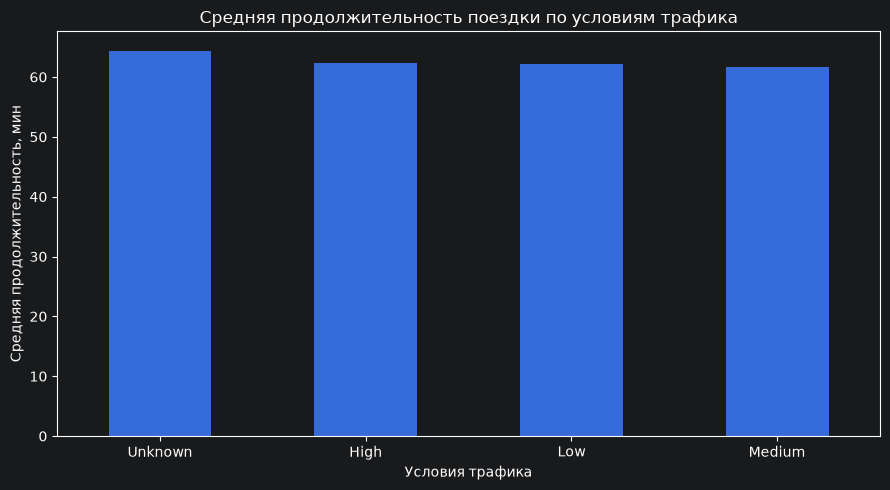

In [63]:
traffic_duration = (
    df.groupby("Traffic_Conditions")["Trip_Duration_Minutes"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

traffic_duration.plot(kind="bar")

plt.title("Средняя продолжительность поездки по условиям трафика")
plt.xlabel("Условия трафика")
plt.ylabel("Средняя продолжительность, мин")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Приведённый выше график хорошо демонстрирует факт, что датасет является синтетическим, т.к. согласно ему средняя продолжительность поездки не зависит от времени суток, что вряд ли можно считать правдой.

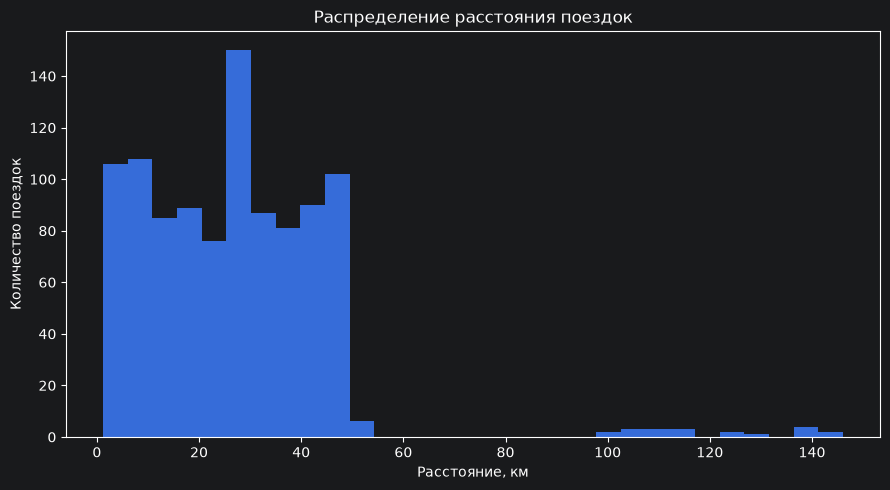

In [64]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Trip_Distance_km"],
    bins=30
)

plt.title("Распределение расстояния поездок")
plt.xlabel("Расстояние, км")
plt.ylabel("Количество поездок")
plt.tight_layout()
plt.show()

Приведённый график подтверждает наличие выборосов в данных, о чем говорит интервал значений (55; 97), в котором остутсвуют какие-либо данные, при этом слева от него данных много, а справа значительно меньше.


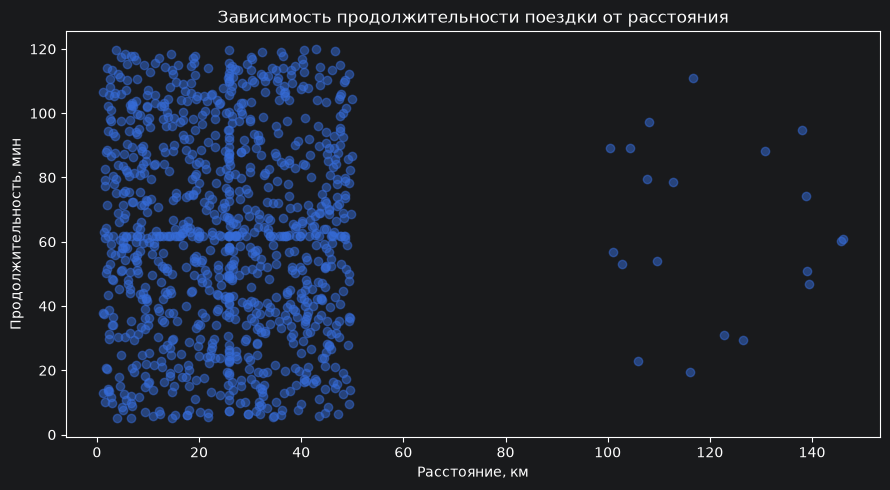

In [65]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Trip_Distance_km"],
    df["Trip_Duration_Minutes"],
    alpha=0.5
)

plt.title("Зависимость продолжительности поездки от расстояния")
plt.xlabel("Расстояние, км")
plt.ylabel("Продолжительность, мин")
plt.tight_layout()
plt.show()

По полученному выше графику можно хорошо заметить, что данные синтетические: расстояние и
 продолжительность распределены равномерно и к расстоянию добавлены выбросы. Также данный график подтверждает отсутствие корреляции между расстоянием и длительностью поездки, т.к. точки распределены равномерно по прямоугольнику значений и не содержат явных трендов (за исключением ярко выраженных средних значений).

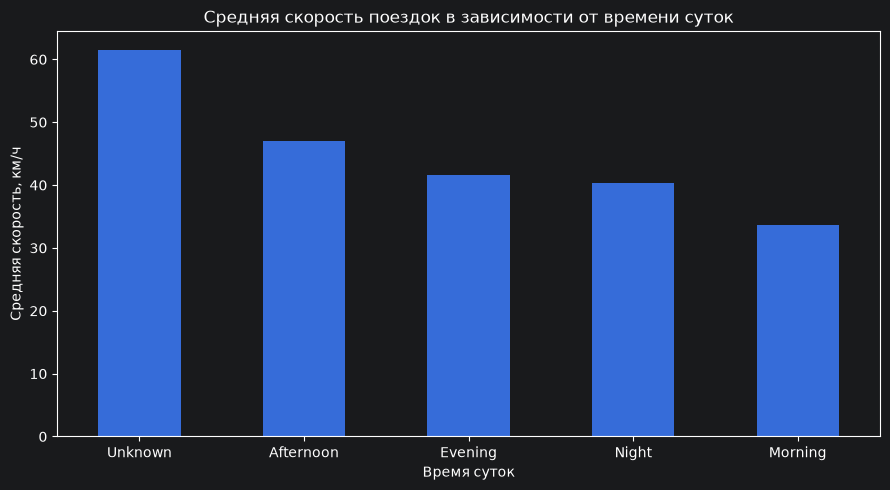

In [66]:
speed_by_time = (
    df.groupby("Time_of_Day")["Average_Speed_kmh"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

speed_by_time.plot(kind="bar")

plt.title("Средняя скорость поездок в зависимости от времени суток")
plt.xlabel("Время суток")
plt.ylabel("Средняя скорость, км/ч")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Данный график показывает, что хотя датасет синтетический, но в нем учтена потенциальная зависимость средней скорости поездки от времени суток (а точнее дистанции и продолжительности, т.к. средняя скорость - вычисляемое значение, которого не было в исходных данных), в которое она происходит.

# Экспорт результатов

In [67]:
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

In [68]:
csv_path = output_dir / "taxi_trips_clean.csv"

df.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"CSV сохранён: {csv_path}")

CSV сохранён: output\taxi_trips_clean.csv


In [69]:
parquet_path = output_dir / "taxi_trips_clean.parquet"

df.to_parquet(
    parquet_path,
    index=False
)

print(f"Parquet сохранён: {parquet_path}")

Parquet сохранён: output\taxi_trips_clean.parquet


In [70]:
json_path = output_dir / "taxi_trips_clean.json"

df.to_json(
    json_path,
    orient="records",
    force_ascii=False,
    indent=2
)

print(f"JSON сохранён: {json_path}")

JSON сохранён: output\taxi_trips_clean.json


In [71]:
files = {
    "CSV": csv_path,
    "Parquet": parquet_path,
    "JSON": json_path
}

print("Сравнение размеров файлов")
for name, path in files.items():
    size_kb = path.stat().st_size / 1024
    print(f"{name}: {size_kb:.2f} КБ")

Сравнение размеров файлов
CSV: 86.49 КБ
Parquet: 42.26 КБ
JSON: 344.92 КБ


In [72]:
df_csv = pd.read_csv(csv_path)
df_parquet = pd.read_parquet(parquet_path)
df_json = pd.read_json(json_path)

print("Проверка повторного чтения")
print("Исходный очищенный датасет:", df.shape)
print("После чтения CSV:", df_csv.shape)
print("После чтения Parquet:", df_parquet.shape)
print("После чтения JSON:", df_json.shape)

Проверка повторного чтения
Исходный очищенный датасет: (1000, 12)
После чтения CSV: (1000, 12)
После чтения Parquet: (1000, 12)
После чтения JSON: (1000, 12)


In [73]:
print("CSV совпадает с исходным:", df.equals(df_csv))

print("Parquet совпадает с исходным:", df.equals(df_parquet))

CSV совпадает с исходным: False
Parquet совпадает с исходным: True


In [74]:
print("Типы в df:")
print(df.dtypes)

print("\nТипы в df_csv:")
print(df_csv.dtypes)

Типы в df:
Trip_Distance_km          float64
Time_of_Day              category
Day_of_Week              category
Passenger_Count           float64
Traffic_Conditions       category
Weather                  category
Base_Fare                 float64
Per_Km_Rate               float64
Per_Minute_Rate           float64
Trip_Duration_Minutes     float64
Trip_Price                float64
Average_Speed_kmh         float64
dtype: object

Типы в df_csv:
Trip_Distance_km         float64
Time_of_Day                  str
Day_of_Week                  str
Passenger_Count          float64
Traffic_Conditions           str
Weather                      str
Base_Fare                float64
Per_Km_Rate              float64
Per_Minute_Rate          float64
Trip_Duration_Minutes    float64
Trip_Price               float64
Average_Speed_kmh        float64
dtype: object


Несовпадение исходного датасета и выгруженного из csv связано с автоматическим присвоением типов данных при чтении, отличных от заданных вручную.

# Выводы
На основании выполненных операций можно сформулировать следующие выводы, относящиеся именно к найденному синтетическому датасету с ценами поездок на такси:
1. О характеристиках поездок.
Среднее расстояние поездки составляет 27 км, а средняя продолжительность - 62 минуты. Это характеризует типичную поездку в исследуемом наборе данных.
2. О взаимосвязи расстояния и продолжительности поездки.
Между Trip_Distance_km и Trip_Duration_Minutes наблюдается слабая отрицательная корреляция со значением -0.02. Это означает между данными характеристиками нет линейной зависимости, т.к. на продолжительность поездки влияет не только лишь её дистанция.
3. О времени суток.
Средняя скорость поездок отличается в зависимости от Time_of_Day, что позволяет сравнить особенности поездок в различные части суток.
4. О типах данных.
Для эффективной работы с данными помимо эффективности алгоритмов также важно эффективное хранение, на примере выбранного датасета хорошо видно, что простая замена типов 4 признаков может сократить размер датасета почти в 2 раза (с 0.11 Мб до 0.06 Мб).
5. О выбросах.
Методом межквартильного размаха (IQR) были обнаружены потенциальные выбросы в дистанции поездок, которые затем были подтверждены визуализацией: между выбросами и остальными значениями параметра существует интервал, в котором нет ни одной записи.
6. О пропущенных значениях.
В исходном наборе присутствуют пропуски во всех признаках. Числовые значения были восстановлены с использованием медианы, а категориальные - диагностическим значением Unknown. Поэтому часть значений в очищенном наборе является восстановленной, а не исходной информацией. Т.к. датасет является синтетическим, то пропуски в нем скорее всего сделаны намеренно с целью имитации проблем со сбором реальных данных, когда часть значений не фиксируется или теряется при передаче.
7. Об ограниченности набора признаков.
Датасет содержит характеристики поездки, но не содержит ряда потенциально важных факторов, например времени начала поездки, региона в котором совершена поездка и др. Поэтому результаты анализа нельзя распространять на все поездки такси без дополнительных данных.

1. Почему dtype числового столбца не гарантирует, что признак является количественным?
Dtype отражает лишь способ хранения значения, а не его смысл. Числовой столбец может быть идентификатором или кодом категории (например, type_id), для которого арифметические операции (среднее, сумма) не имеют содержательного смысла.

2. Чем DataFrame отличается от NumPy ndarray с точки зрения схемы и типов?
ndarray — однородный массив: все элементы одного dtype, без именованных столбцов. DataFrame — набор столбцов (Series), каждый со своим dtype, с именами столбцов и индексом строк, то есть структура со схемой и метаданными.

3. Какие диагностические задачи решают head(), info() и describe() и почему одна функция не заменяет остальные?
head() проверяет корректность содержимого (парсинг, кодировка). info() показывает структуру: типы столбцов, число непустых значений, объём памяти. describe() даёт статистическую сводку распределения. Каждая решает свою диагностическую задачу и не дублирует остальные.

4. Почему отсутствие пропусков и дубликатов ещё не означает отсутствие проблем качества данных?
Отсутствие NaN и повторов не исключает других проблем: неверных единиц измерения, аномальных значений, несогласованных кодов, неверных типов или смещения выборки по категориям.

5. В каких случаях category уменьшает память и почему?
Экономия достигается при низкой кардинальности признака (мало уникальных значений на фоне большого числа строк): строки заменяются компактными числовыми кодами. При высокой кардинальности выигрыша нет.

6. Чем фильтрация отличается от группировки?
Фильтрация отбирает подмножество строк по условию, не меняя структуру таблицы. Группировка разбивает строки на группы и агрегирует их в сводные показатели, меняя форму результата.

7. Что означает коэффициент корреляции около нуля? Какие выводы из него делать нельзя?
Означает отсутствие выраженной линейной связи. Не означает отсутствие связи вообще (возможна нелинейная зависимость) и не позволяет делать выводы о причинности.

8. Почему правило IQR нельзя использовать как автоматический алгоритм удаления данных?
Правило статистическое и не учитывает предметный смысл значений: при естественно асимметричном распределении оно помечает как «выбросы» значительную долю нормальных наблюдений. Решение об удалении требует проверки происхождения данных.

9. Как выбрать между histogram, bar chart, scatter plot и временным рядом?
Bar chart — сравнение категорий; histogram — форма распределения одного числового признака; scatter plot — связь двух числовых признаков; временной ряд — динамика значения во времени. Выбор определяется структурой данных и вопросом.

10. Почему временной ряд нельзя строить по индексу строк, если индекс не является временем?
Порядок строк в файле обычно не связан со временем события, поэтому график «значение от номера строки» может показать мнимую динамику, отсутствующую в реальности.

11. Какие преимущества Parquet даёт аналитическому pipeline по сравнению с CSV?
Колоночный бинарный формат: хранит схему и типы вместе с данными, поддерживает сжатие и выборочное чтение столбцов — быстрее и компактнее CSV для аналитических нагрузок, особенно при последующей работе со Spark.

12. Почему воспроизводимый notebook должен корректно выполняться командой Run All после перезапуска ядра?
Это проверяет отсутствие скрытого состояния (ячейки, выполненные не по порядку, ручные шаги вне кода). Только чистое выполнение сверху вниз подтверждает, что notebook детерминированно воспроизводим.